# Step 2 - Exploratory Data Analysis
**Objective 1:** analyse historical transactions to identify purchasing patterns and customer behaviour.

Input: the clean files from Step 1 (`data/clean_sales.csv`, `data/clean_returns.csv`). Click **Run All**.

**Sections**
1. Setup and overview
2. Sales trends
3. Seasonality (month, weekday, hour)
4. Countries
5. Products and concentration
6. Customer behaviour
7. New vs returning customers and cohort retention
8. Returns
9. Key findings and what they mean for churn modelling

Charts are shown here and also saved to the `figures/` folder. All the findings are written to `eda_summary.txt`.

## 1. Setup and overview

In [11]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 50
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

DATA, FIG = "data", "figures"
os.makedirs(FIG, exist_ok=True)
findings = []          # every key finding is collected here and printed at the end


def save(name):
    plt.tight_layout()
    plt.savefig(f"{FIG}/{name}.png", dpi=120)
    plt.show()


def note(text):
    findings.append(text)
    print("->", text)


sales = pd.read_csv(f"{DATA}/clean_sales.csv", parse_dates=["InvoiceDate"], dtype={"StockCode": str})
returns = pd.read_csv(f"{DATA}/clean_returns.csv", parse_dates=["InvoiceDate"], dtype={"StockCode": str})
print(f"sales: {len(sales):,} rows | returns: {len(returns):,} rows")

# --- data quirk: very large order lines that were later cancelled in full (sale and cancellation cancel out)
big = sales[sales["Revenue"] >= 20000].reset_index()
pairs = big.merge(returns.reset_index()[["index", "CustomerID", "StockCode", "ReturnQty", "InvoiceDate"]],
                  left_on=["CustomerID", "StockCode", "Quantity"], right_on=["CustomerID", "StockCode", "ReturnQty"],
                  suffixes=("", "_ret"))
pairs = pairs[pairs["InvoiceDate_ret"] >= pairs["InvoiceDate"]]
print("\nLarge order lines that were cancelled in full afterwards (removed from this analysis):")
display(pairs[["Invoice", "Description", "Quantity", "Revenue", "InvoiceDate", "InvoiceDate_ret"]]
        .rename(columns={"InvoiceDate": "SoldOn", "InvoiceDate_ret": "CancelledOn"}))
sales = sales.drop(index=pairs["index"].unique())
returns = returns.drop(index=pairs["index_ret"].unique())
print(f"Removed {len(pairs)} sale line(s) and matching cancellation(s). Without this, they inflate revenue in one month.")

# one row per order (invoice)
orders = (sales.groupby(["CustomerID", "Invoice"])
               .agg(Date=("InvoiceDate", "min"), Value=("Revenue", "sum"),
                    Items=("Quantity", "sum"), Lines=("StockCode", "nunique"))
               .reset_index())

total = sales["Revenue"].sum()
ret_total = returns["ReturnValue"].sum()
overview = pd.Series({
    "Period": f"{sales['InvoiceDate'].min():%d %b %Y} to {sales['InvoiceDate'].max():%d %b %Y}",
    "Total revenue": f"{total:,.0f}",
    "Orders": f"{len(orders):,}",
    "Customers": f"{sales['CustomerID'].nunique():,}",
    "Products sold": f"{sales['StockCode'].nunique():,}",
    "Countries": sales["Country"].nunique(),
    "Average order value": f"{orders['Value'].mean():,.2f}",
    "Median order value": f"{orders['Value'].median():,.2f}",
    "Average product lines per order": f"{orders['Lines'].mean():.1f}",
    "Returned value (% of sales)": f"{ret_total:,.0f} ({ret_total / total:.1%})",
}, name="value")
overview.to_frame()

sales: 776,575 rows | returns: 17,586 rows

Large order lines that were cancelled in full afterwards (removed from this analysis):


,Invoice,Description,Quantity,Revenue,SoldOn,CancelledOn
0,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,"77,183.60",2011-01-18 10:01:00,2011-01-18 10:17:00
1,556444,PICNIC BASKET WICKER SMALL,60,"38,970.00",2011-06-10 15:28:00,2011-06-10 15:39:00
2,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,"168,469.60",2011-12-09 09:15:00,2011-12-09 09:27:00


Removed 3 sale line(s) and matching cancellation(s). Without this, they inflate revenue in one month.


,value
Period,01 Dec 2009 to 09 Dec 2011
Total revenue,"16,783,393"
Orders,"36,591"
Customers,"5,852"
Products sold,"4,618"
Countries,41
Average order value,458.68
Median order value,302.54
Average product lines per order,20.9
Returned value (% of sales),"464,003 (2.8%)"


## 2. Sales trends
Revenue, number of active customers and average order value per month. December 2011 contains only 9 days of data, so it is left out of the charts and the growth calculation.

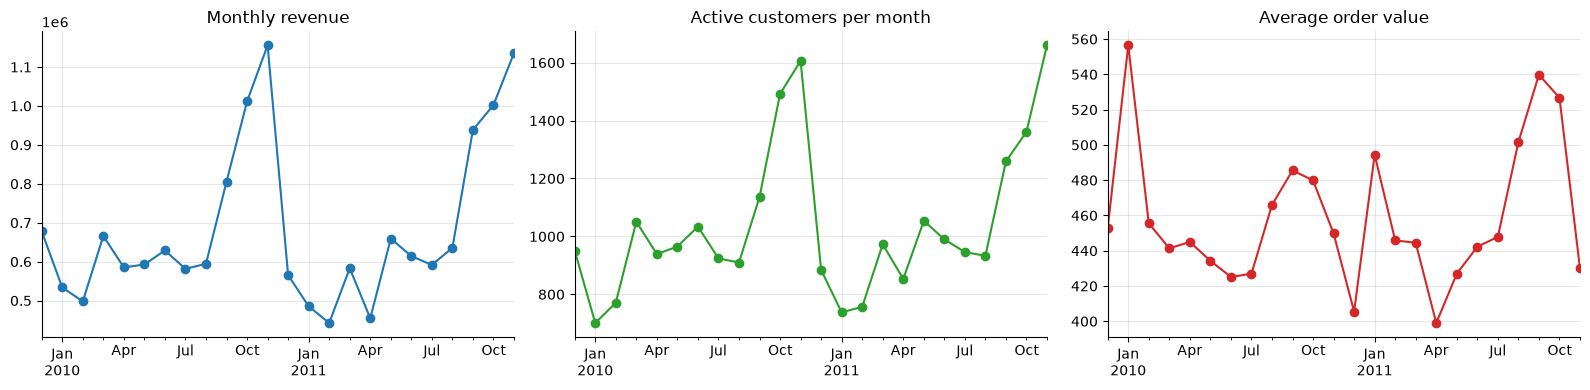


-> Revenue Jan-Nov 2011 vs Jan-Nov 2010: -1.4%; active customers: +1.0% - the business is essentially flat year on year.
-> Best month: Nov 2010 (1,155,978); weakest full month: Feb 2011 (442,294).
-> Average order value is stable at about 459 (range 399 - 557).


,Revenue,Orders,Customers,AOV
InvoiceMonth,,,,
2011-07-01,"591,603.79",1321,946,447.85
2011-08-01,"635,514.38",1267,933,501.59
2011-09-01,"938,752.63",1739,1259,539.82
2011-10-01,"1,002,326.56",1903,1361,526.71
2011-11-01,"1,135,997.00",2642,1660,429.98
2011-12-01,"343,758.48",775,613,443.56


In [12]:
monthly = (sales.groupby("InvoiceMonth")
                .agg(Revenue=("Revenue", "sum"), Orders=("Invoice", "nunique"),
                     Customers=("CustomerID", "nunique")))
monthly["AOV"] = monthly["Revenue"] / monthly["Orders"]
monthly_rev_str = monthly["Revenue"].copy()          # keep a string-indexed copy for later
monthly.index = pd.to_datetime(monthly.index)
full = monthly.iloc[:-1]                              # drop the partial last month (Dec 2011)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
full["Revenue"].plot(ax=ax[0], marker="o"); ax[0].set_title("Monthly revenue")
full["Customers"].plot(ax=ax[1], marker="o", color="tab:green"); ax[1].set_title("Active customers per month")
full["AOV"].plot(ax=ax[2], marker="o", color="tab:red"); ax[2].set_title("Average order value")
for a in ax: a.set_xlabel("")
save("01_monthly_trends")

def ytd(y, col="Revenue"):
    s = sales[(sales["InvoiceDate"].dt.year == y) & (sales["InvoiceDate"].dt.month <= 11)]
    return s["Revenue"].sum() if col == "Revenue" else s["CustomerID"].nunique()

g_rev = ytd(2011) / ytd(2010) - 1
g_cust = ytd(2011, "cust") / ytd(2010, "cust") - 1
print()
note(f"Revenue Jan-Nov 2011 vs Jan-Nov 2010: {g_rev:+.1%}; active customers: {g_cust:+.1%}"
     + (" - the business is essentially flat year on year." if abs(g_rev) < 0.03 else "."))
note(f"Best month: {full['Revenue'].idxmax():%b %Y} ({full['Revenue'].max():,.0f}); "
     f"weakest full month: {full['Revenue'].idxmin():%b %Y} ({full['Revenue'].min():,.0f}).")
note(f"Average order value is stable at about {full['AOV'].mean():,.0f} "
     f"(range {full['AOV'].min():,.0f} - {full['AOV'].max():,.0f}).")
monthly.tail(6)

## 3. Seasonality
2010 is a full calendar year and 2011 is complete up to November, so the two years can be compared month by month. The heatmap shows when during the week and day customers buy.

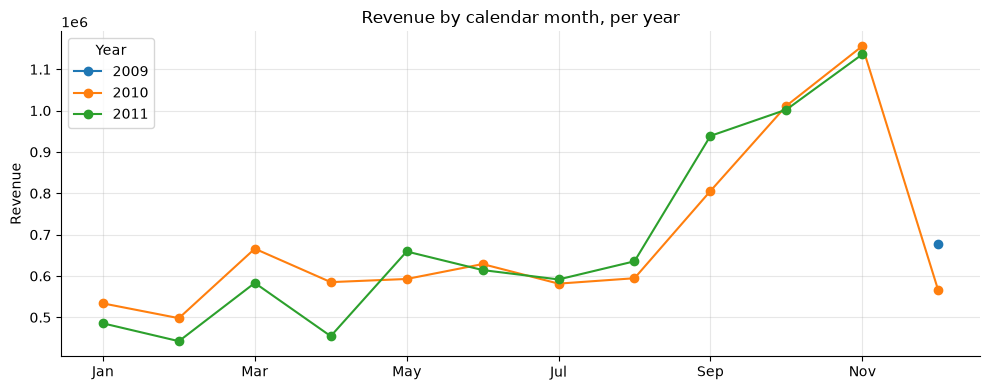


-> Sep-Nov accounted for 36% of all 2010 revenue (pre-Christmas stocking season).
-> Peak month: Nov in 2010 and Nov in 2011; quietest month of 2010: Feb.


In [13]:
m = monthly.copy()
m["Year"], m["Mon"] = m.index.year, m.index.month
pivot = m.pivot(index="Mon", columns="Year", values="Revenue")
pivot.loc[12, 2011] = np.nan                         # partial month
pivot.index = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

pivot.plot(marker="o", figsize=(10, 4), title="Revenue by calendar month, per year")
plt.ylabel("Revenue")
save("02_seasonality_by_month")

rev_2010 = sales[sales["InvoiceDate"].dt.year == 2010]["Revenue"].sum()
q4_2010 = sales[(sales["InvoiceDate"].dt.year == 2010) & (sales["InvoiceDate"].dt.month.isin([9, 10, 11]))]["Revenue"].sum()
print()
note(f"Sep-Nov accounted for {q4_2010 / rev_2010:.0%} of all 2010 revenue (pre-Christmas stocking season).")
note(f"Peak month: {pivot[2010].idxmax()} in 2010 and {pivot[2011].idxmax()} in 2011; "
     f"quietest month of 2010: {pivot[2010].idxmin()}.")

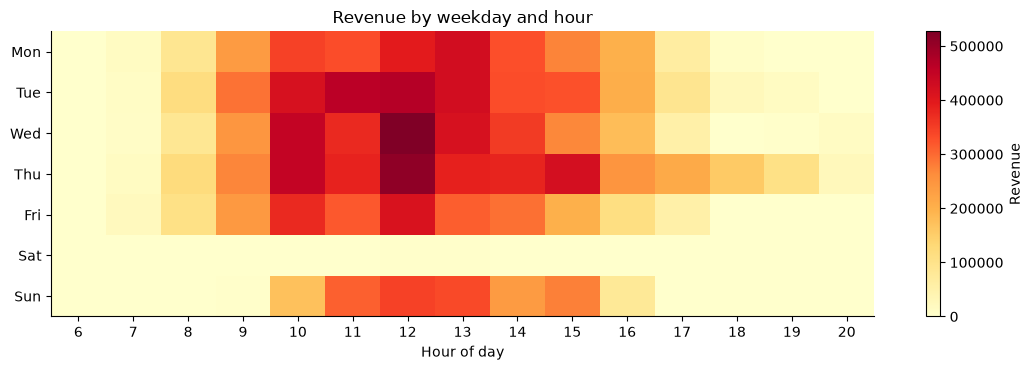


-> Busiest weekday: Thu; busiest hour: 12:00. 78% of revenue is booked between 10:00 and 15:59.
-> Days with no sales at all: none.


In [14]:
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
heat = (sales.assign(Day=sales["InvoiceDate"].dt.dayofweek, Hour=sales["InvoiceDate"].dt.hour)
             .pivot_table(index="Day", columns="Hour", values="Revenue", aggfunc="sum")
             .reindex(range(7)).fillna(0))

fig, ax = plt.subplots(figsize=(11, 3.8))
im = ax.imshow(heat.values, aspect="auto", cmap="YlOrRd")
ax.set_xticks(range(len(heat.columns))); ax.set_xticklabels(heat.columns)
ax.set_yticks(range(7)); ax.set_yticklabels(days); ax.grid(False)
ax.set_title("Revenue by weekday and hour"); ax.set_xlabel("Hour of day")
plt.colorbar(im, ax=ax, label="Revenue")
save("03_weekday_hour_heatmap")

wd = heat.sum(axis=1); hr = heat.sum(axis=0)
print()
note(f"Busiest weekday: {days[int(wd.idxmax())]}; busiest hour: {int(hr.idxmax())}:00. "
     f"{hr.loc[10:15].sum() / hr.sum():.0%} of revenue is booked between 10:00 and 15:59.")
no_sales = [days[i] for i in range(7) if wd[i] == 0]
note(f"Days with no sales at all: {', '.join(no_sales) if no_sales else 'none'}.")

## 4. Countries

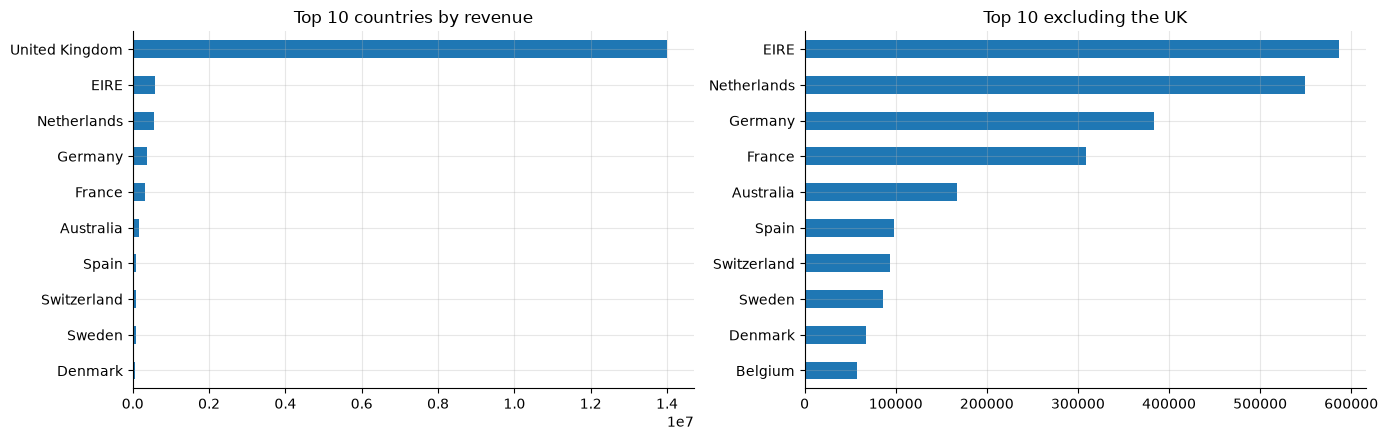


-> The UK generates 83% of revenue and 91% of customers; the next markets are EIRE, Netherlands, Germany, France.
-> Among countries with 5+ customers, Netherlands has the highest revenue per customer (24,990 vs 2,625 for the UK).


,Revenue,Customers,Orders,Share_%,Revenue_per_customer
Country,,,,,
United Kingdom,"14,003,583.70",5334,33358,83.44,"2,625.34"
EIRE,"586,626.08",3,528,3.50,"195,542.03"
Netherlands,"549,773.41",22,216,3.28,"24,989.70"
Germany,"383,289.00",107,753,2.28,"3,582.14"
France,"309,403.16",93,590,1.84,"3,326.92"
Australia,"167,800.01",15,89,1.00,"11,186.67"
Spain,"97,766.75",38,144,0.58,"2,572.81"
Switzerland,"93,400.94",22,82,0.56,"4,245.50"
Sweden,"86,045.14",19,98,0.51,"4,528.69"


In [15]:
ctry = (sales.groupby("Country")
             .agg(Revenue=("Revenue", "sum"), Customers=("CustomerID", "nunique"),
                  Orders=("Invoice", "nunique")))
ctry["Share_%"] = ctry["Revenue"] / ctry["Revenue"].sum() * 100
ctry["Revenue_per_customer"] = ctry["Revenue"] / ctry["Customers"]
ctry = ctry.sort_values("Revenue", ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ctry["Revenue"].head(10).sort_values().plot.barh(ax=ax[0], title="Top 10 countries by revenue")
ctry.drop("United Kingdom")["Revenue"].head(10).sort_values().plot.barh(ax=ax[1], title="Top 10 excluding the UK")
for a in ax: a.set_ylabel("")
save("04_countries")

uk_share = ctry.loc["United Kingdom", "Share_%"]
uk_cust = ctry.loc["United Kingdom", "Customers"] / sales["CustomerID"].nunique()
print()
note(f"The UK generates {uk_share:.0f}% of revenue and {uk_cust:.0%} of customers; "
     f"the next markets are {', '.join(ctry.drop('United Kingdom').head(4).index)}.")
big = ctry[ctry["Customers"] >= 5].drop("United Kingdom")
best = big["Revenue_per_customer"].idxmax()
note(f"Among countries with 5+ customers, {best} has the highest revenue per customer "
     f"({big.loc[best, 'Revenue_per_customer']:,.0f} vs {ctry.loc['United Kingdom', 'Revenue_per_customer']:,.0f} for the UK).")
ctry.head(10)

## 5. Products and concentration
How concentrated is revenue in a few products, and how long is the tail of rarely sold items?

Top 10 products by revenue


,StockCode,Description,Revenue,Units,Customers,Orders
0,22423,REGENCY CAKESTAND 3 TIER,"277,656.25",24124,1314,3317
1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"247,203.36",91814,1490,4895
2,85099B,JUMBO BAG RED RETROSPOT,"167,920.64",93436,978,3260
3,84879,ASSORTED COLOUR BIRD ORNAMENT,"124,351.86",78234,1010,2652
4,47566,PARTY BUNTING,"103,283.38",23460,894,2077
5,22086,PAPER CHAIN KIT 50'S CHRISTMAS,"76,598.18",28380,896,1691
6,79321,CHILLI LIGHTS,"69,084.30",14843,304,922
7,22386,JUMBO BAG PINK POLKADOT,"67,769.76",37338,601,1767
8,48138,DOORMAT UNION FLAG,"64,269.95",9879,678,1511
9,85099F,JUMBO BAG STRAWBERRY,"64,127.77",35842,549,1514


Top 10 products by number of customers who bought them


,StockCode,Description,Revenue,Units,Customers,Orders
0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"247,203.36",91814,1490,4895
1,22423,REGENCY CAKESTAND 3 TIER,"277,656.25",24124,1314,3317
2,22138,BAKING SET 9 PIECE RETROSPOT,"43,070.91",9035,1137,1742
3,21212,PACK OF 72 RETROSPOT CAKE CASES,"43,390.03",89850,1115,2508
4,84879,ASSORTED COLOUR BIRD ORNAMENT,"124,351.86",78234,1010,2652
5,85099B,JUMBO BAG RED RETROSPOT,"167,920.64",93436,978,3260
6,22139,RETROSPOT TEA SET CERAMIC 11 PC,"47,531.45",10052,941,1838
7,22086,PAPER CHAIN KIT 50'S CHRISTMAS,"76,598.18",28380,896,1691
8,47566,PARTY BUNTING,"103,283.38",23460,894,2077
9,22469,HEART OF WICKER SMALL,"43,316.54",26193,886,1779


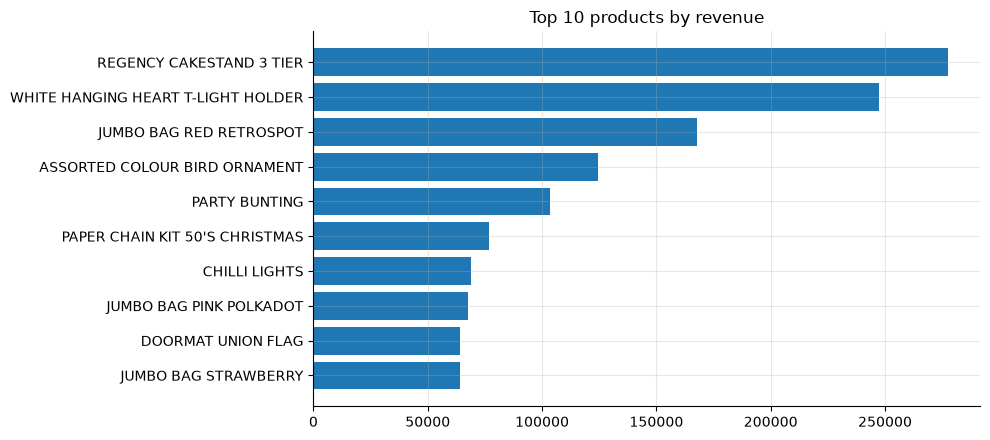

In [16]:
prod = (sales.groupby(["StockCode", "Description"])
             .agg(Revenue=("Revenue", "sum"), Units=("Quantity", "sum"),
                  Customers=("CustomerID", "nunique"), Orders=("Invoice", "nunique"))
             .reset_index())

print("Top 10 products by revenue")
display(prod.sort_values("Revenue", ascending=False).head(10).reset_index(drop=True))
print("Top 10 products by number of customers who bought them")
display(prod.sort_values("Customers", ascending=False).head(10).reset_index(drop=True))

top = prod.sort_values("Revenue", ascending=False).head(10).sort_values("Revenue")
plt.figure(figsize=(10, 4.5))
plt.barh(top["Description"], top["Revenue"]); plt.title("Top 10 products by revenue")
save("05_top_products")

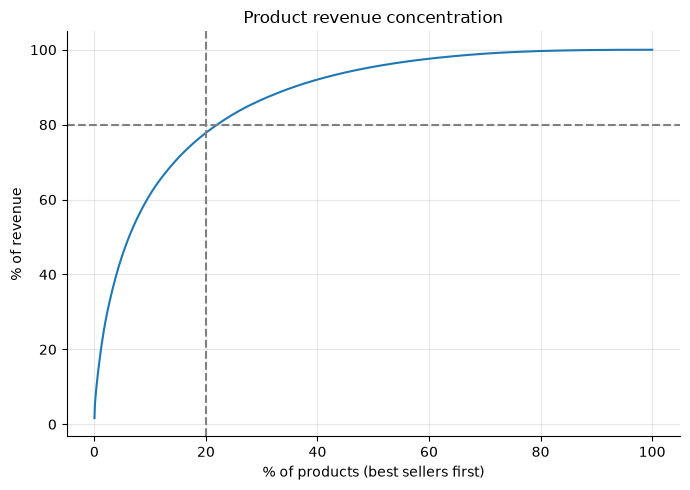


-> The top 20% of products generate 78% of revenue; 1,016 of 4,618 products (22%) make up 80% of revenue.
-> 17% of products were bought by fewer than 10 customers (a long tail that matters for the recommender).


In [17]:
rev_sorted = prod["Revenue"].sort_values(ascending=False).reset_index(drop=True)
cum = rev_sorted.cumsum() / rev_sorted.sum()
x = np.arange(1, len(cum) + 1) / len(cum)

plt.figure(figsize=(7, 5))
plt.plot(x * 100, cum * 100)
plt.axhline(80, ls="--", c="grey"); plt.axvline(20, ls="--", c="grey")
plt.xlabel("% of products (best sellers first)"); plt.ylabel("% of revenue")
plt.title("Product revenue concentration")
save("06_product_pareto")

n80 = int((cum < 0.8).sum() + 1)
top20 = cum.iloc[int(len(cum) * 0.2) - 1]
print()
note(f"The top 20% of products generate {top20:.0%} of revenue; {n80:,} of {len(prod):,} products "
     f"({n80 / len(prod):.0%}) make up 80% of revenue.")
niche = (prod["Customers"] < 10).mean()
note(f"{niche:.0%} of products were bought by fewer than 10 customers (a long tail that matters for the recommender).")

## 6. Customer behaviour
Orders per customer, order size, spending concentration and the time between orders. The time between orders is especially important because it decides how churn should be defined in the next step.

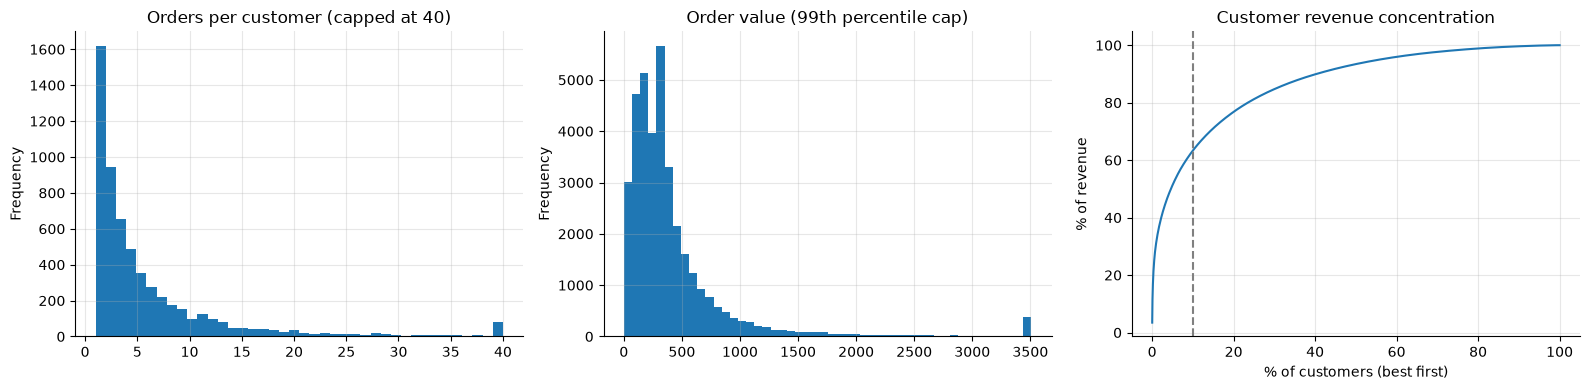


-> 28% of customers placed only one order; the median customer placed 3 orders and the most active placed 373.
-> The top 10% of customers generate 63% of revenue.
-> The median order is worth 303 but the mean is 459: a few very large (wholesale) orders pull the average up.


In [18]:
cust = (sales.groupby("CustomerID")
             .agg(Revenue=("Revenue", "sum"), Orders=("Invoice", "nunique"),
                  Products=("StockCode", "nunique"), First=("InvoiceDate", "min"),
                  Last=("InvoiceDate", "max")))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
cust["Orders"].clip(upper=40).plot.hist(bins=40, ax=ax[0], title="Orders per customer (capped at 40)")
orders["Value"].clip(upper=orders["Value"].quantile(0.99)).plot.hist(bins=50, ax=ax[1],
                                                                       title="Order value (99th percentile cap)")
c_sorted = cust["Revenue"].sort_values(ascending=False)
cc = c_sorted.cumsum() / c_sorted.sum()
ax[2].plot(np.arange(1, len(cc) + 1) / len(cc) * 100, cc * 100)
ax[2].axvline(10, ls="--", c="grey"); ax[2].set_title("Customer revenue concentration")
ax[2].set_xlabel("% of customers (best first)"); ax[2].set_ylabel("% of revenue")
save("07_customer_distributions")

one_time = (cust["Orders"] == 1).mean()
top10 = cc.iloc[int(len(cc) * 0.1) - 1]
print()
note(f"{one_time:.0%} of customers placed only one order; the median customer placed {cust['Orders'].median():.0f} orders "
     f"and the most active placed {cust['Orders'].max()}.")
note(f"The top 10% of customers generate {top10:.0%} of revenue.")
note(f"The median order is worth {orders['Value'].median():,.0f} but the mean is {orders['Value'].mean():,.0f}: "
     f"a few very large (wholesale) orders pull the average up.")

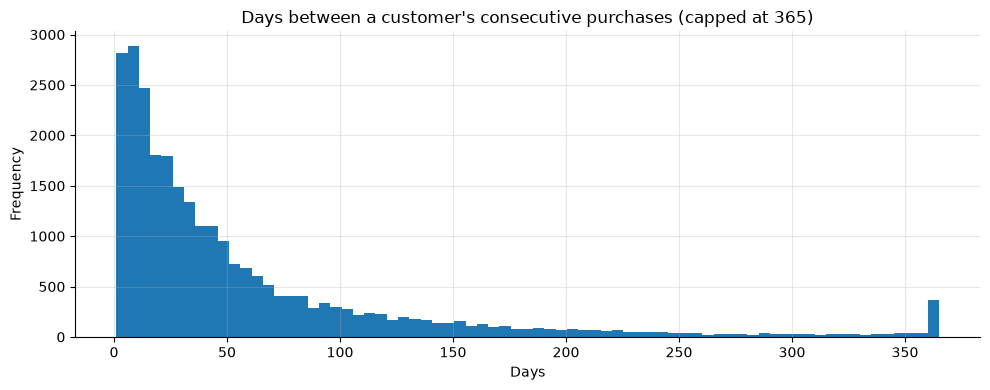


-> Time between purchases: median 32 days, 75% within 70 days, 90% within 148 days.


In [19]:
# days between consecutive purchase days for each customer
days_df = (orders.assign(Day=orders["Date"].dt.normalize())
                 .drop_duplicates(["CustomerID", "Day"]).sort_values(["CustomerID", "Day"]))
days_df["Gap"] = days_df.groupby("CustomerID")["Day"].diff().dt.days
gaps = days_df["Gap"].dropna()

plt.figure(figsize=(10, 4))
gaps.clip(upper=365).plot.hist(bins=73)
plt.title("Days between a customer's consecutive purchases (capped at 365)")
plt.xlabel("Days")
save("08_purchase_gaps")

p50, p75, p90 = gaps.quantile([0.5, 0.75, 0.9])
print()
note(f"Time between purchases: median {p50:.0f} days, 75% within {p75:.0f} days, 90% within {p90:.0f} days.")

## 7. New vs returning customers and cohort retention
A *cohort* is the group of customers whose first purchase fell in the same month. The heatmap shows what share of each cohort buys again 1, 2, 3... months later. Customers already active in December 2009 are not true new customers (we cannot see their earlier history), so they are excluded from the cohort chart.

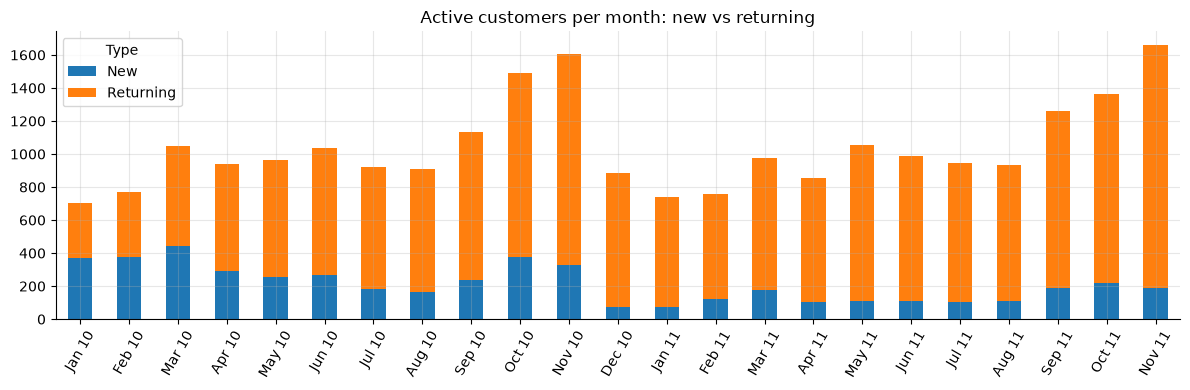


-> On average 80% of monthly active customers are returning customers, so the business depends on repeat buyers.


In [20]:
first_month = sales.groupby("CustomerID")["InvoiceMonth"].min()
flag = sales["InvoiceMonth"] == sales["CustomerID"].map(first_month)
nr = (sales.assign(Type=np.where(flag, "New", "Returning"))
           .groupby(["InvoiceMonth", "Type"])["CustomerID"].nunique().unstack(fill_value=0))
nr = nr.iloc[1:-1]                                    # drop Dec 2009 (everyone looks new) and partial Dec 2011
nr.index = pd.to_datetime(nr.index).strftime("%b %y")   # plain text labels: bar charts with a date index fail in newer pandas

nr.plot.bar(stacked=True, figsize=(12, 4), title="Active customers per month: new vs returning", rot=60)
plt.xlabel("")
save("09_new_vs_returning")

print()
note(f"On average {nr['Returning'].sum() / nr.sum().sum():.0%} of monthly active customers are returning customers, "
     f"so the business depends on repeat buyers.")

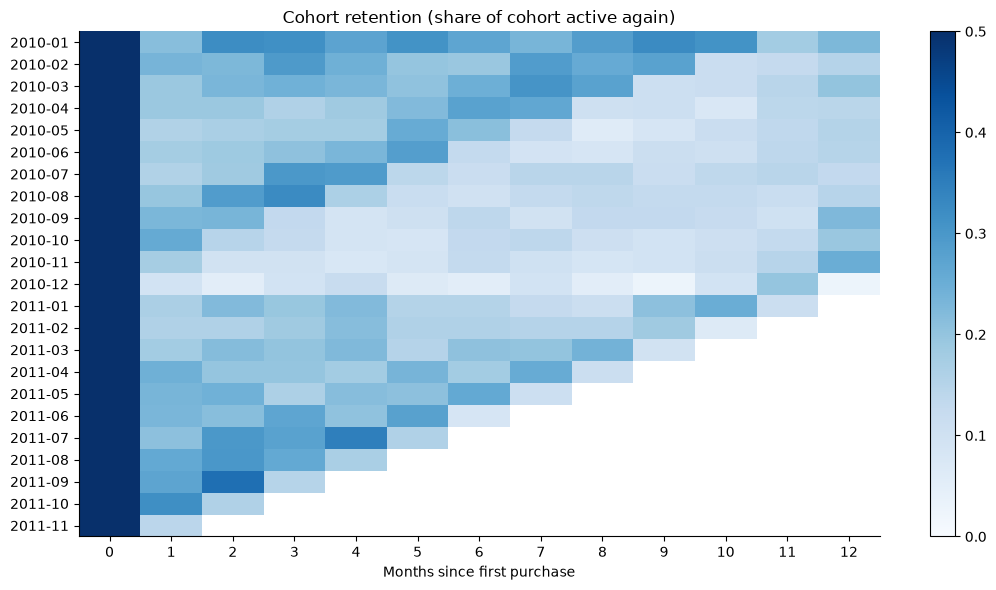


-> Average cohort retention: month 1 = 20%, month 3 = 22%, month 6 = 18%, month 12 = 18%.


In [21]:
act = sales[["CustomerID", "InvoiceMonth"]].drop_duplicates().copy()
act["P"] = act["InvoiceMonth"].str[:4].astype(int) * 12 + act["InvoiceMonth"].str[5:7].astype(int)
act["Cohort"] = act.groupby("CustomerID")["P"].transform("min")
act["Age"] = act["P"] - act["Cohort"]

cohort = act.groupby(["Cohort", "Age"])["CustomerID"].nunique().unstack()
retention = cohort.div(cohort[0], axis=0)
retention.index = [f"{(p - 1) // 12}-{(p - 1) % 12 + 1:02d}" for p in retention.index]
retention = retention.loc["2010-01":"2011-11"].iloc[:, :13]       # real cohorts, first 12 months

fig, ax = plt.subplots(figsize=(11, 6))
im = ax.imshow(retention.values, aspect="auto", cmap="Blues", vmin=0, vmax=0.5)
ax.set_xticks(range(retention.shape[1])); ax.set_yticks(range(len(retention)))
ax.set_yticklabels(retention.index); ax.grid(False)
ax.set_xlabel("Months since first purchase"); ax.set_title("Cohort retention (share of cohort active again)")
plt.colorbar(im, ax=ax)
save("10_cohort_retention")

full_cohorts = retention.loc["2010-01":"2010-11"]
r = full_cohorts.mean()
print()
note(f"Average cohort retention: month 1 = {r[1]:.0%}, month 3 = {r[3]:.0%}, month 6 = {r[6]:.0%}, month 12 = {r[12]:.0%}.")

## 8. Returns
Cancelled and returned lines, as a share of sales and by product. One enormous cancelled order exists in this data set, so the return rate is also shown without it.

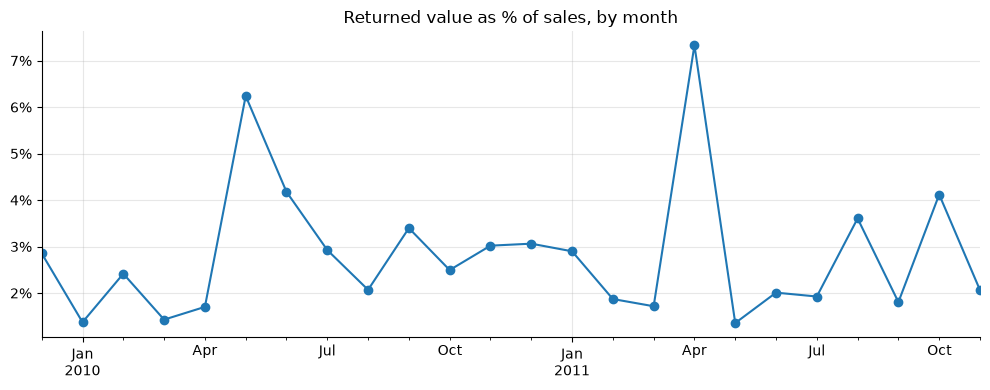


-> Returns equal 2.8% of sales value (2.6% without the single largest cancelled invoice, C550456).
-> 42% of customers have at least one return; 5.1% of all customers return more than 10% of what they buy.

Most returned products by value (excluding the largest cancelled invoice):


,,ReturnValue,Units
StockCode,Description,,
22423,REGENCY CAKESTAND 3 TIER,"16,545.30",1450
71477,COLOUR GLASS. STAR T-LIGHT HOLDER,"7,164.12",2574
79323W,WHITE CHERRY LIGHTS,"6,387.35",1083
21843,RED RETROSPOT CAKE STAND,"5,259.30",586
84078A,SET/4 WHITE RETRO STORAGE CUBES,"5,187.65",147
23113,PANTRY CHOPPING BOARD,"4,803.06",946
85123A,WHITE HANGING HEART T-LIGHT HOLDER,"4,447.90",1701
22138,BAKING SET 9 PIECE RETROSPOT,"4,043.05",857


In [22]:
ret_month = returns.groupby("InvoiceMonth")["ReturnValue"].sum()
rate = (ret_month / monthly_rev_str).dropna()
rate.index = pd.to_datetime(rate.index)

plt.figure(figsize=(10, 4))
rate.iloc[:-1].plot(marker="o")
plt.title("Returned value as % of sales, by month"); plt.xlabel("")
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
save("11_return_rate")

by_inv = returns.groupby("Invoice")["ReturnValue"].sum()
biggest = by_inv.idxmax()
rate_all = ret_total / total
rate_ex = (ret_total - by_inv.max()) / total
print()
note(f"Returns equal {rate_all:.1%} of sales value ({rate_ex:.1%} without the single largest cancelled invoice, {biggest}).")

c_ret = returns.groupby("CustomerID")["ReturnValue"].sum()
c_rate = (c_ret / cust["Revenue"].reindex(c_ret.index)).dropna()
note(f"{len(c_ret) / len(cust):.0%} of customers have at least one return; "
     f"{(c_rate > 0.10).sum() / len(cust):.1%} of all customers return more than 10% of what they buy.")

print("\nMost returned products by value (excluding the largest cancelled invoice):")
display(returns[returns["Invoice"] != biggest]
        .groupby(["StockCode", "Description"]).agg(ReturnValue=("ReturnValue", "sum"), Units=("ReturnQty", "sum"))
        .sort_values("ReturnValue", ascending=False).head(8))

## 9. Key findings and what they mean for churn modelling

In [23]:
print("KEY FINDINGS")
print("=" * 60)
for i, f in enumerate(findings, 1):
    print(f"{i:2d}. {f}")

print("\nIMPLICATIONS FOR THE CHURN MODEL (Step 3)")
print("=" * 60)
print(f"- Typical gap between purchases is {p50:.0f} days (90% within {p90:.0f}). A churn window of about "
      f"{int(round(p90 / 30) * 30)} days ({int(round(p90 / 30))} months) is therefore defensible: "
      f"a customer silent for that long has broken their normal rhythm.")
print(f"- {one_time:.0%} of customers bought only once, so many have too little history for rich features. "
      f"Expect recency and frequency to dominate.")
print(f"- Spending is concentrated (top 10% = {top10:.0%} of revenue): the retention step should weigh churn "
      f"probability together with customer value.")
print("- Revenue is strongly seasonal: build features and labels with cut-off dates that avoid Sep-Nov distortion, "
      "and test on more than one cut-off date.")
print("- Dec 2011 is partial and Dec 2009 is the left edge of the data: never use them as an outcome window.")

with open("eda_summary.txt", "w", encoding="utf-8") as fh:
    fh.write("KEY FINDINGS\n")
    fh.write("\n".join(f"{i}. {f}" for i, f in enumerate(findings, 1)))
print("\nSaved: eda_summary.txt and the charts in the figures/ folder.")

KEY FINDINGS
 1. Revenue Jan-Nov 2011 vs Jan-Nov 2010: -1.4%; active customers: +1.0% - the business is essentially flat year on year.
 2. Best month: Nov 2010 (1,155,978); weakest full month: Feb 2011 (442,294).
 3. Average order value is stable at about 459 (range 399 - 557).
 4. Sep-Nov accounted for 36% of all 2010 revenue (pre-Christmas stocking season).
 5. Peak month: Nov in 2010 and Nov in 2011; quietest month of 2010: Feb.
 6. Busiest weekday: Thu; busiest hour: 12:00. 78% of revenue is booked between 10:00 and 15:59.
 7. Days with no sales at all: none.
 8. The UK generates 83% of revenue and 91% of customers; the next markets are EIRE, Netherlands, Germany, France.
 9. Among countries with 5+ customers, Netherlands has the highest revenue per customer (24,990 vs 2,625 for the UK).
10. The top 20% of products generate 78% of revenue; 1,016 of 4,618 products (22%) make up 80% of revenue.
11. 17% of products were bought by fewer than 10 customers (a long tail that matters for t